# Домашнее задание 1: Классификация новостей Lenta по топикам

Классический ML — берем датасет lenta-ru-news (title, text, topic) и пытаемся предсказать топик

In [50]:
!pip install -q corus pymorphy3 pymorphy2-dicts-ru razdel


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [51]:
import os
import re
import random
import warnings
import subprocess
from functools import lru_cache

import numpy as np
import pandas as pd
import razdel
import pymorphy3
from corus import load_lenta

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, f1_score, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

import matplotlib.pyplot as plt
import seaborn as sns


## Загрузка данных

Скачиваю lenta-ru-news через corus 100k записей, title+text объединяю — заголовок помогает с топиком

In [52]:
RANDOM_STATE = 42
DATA_PATH = "lenta-ru-news.csv.gz"
DATA_URL = (
    "https://github.com/yutkin/Lenta.Ru-News-Dataset/"
    "releases/download/v1.0/lenta-ru-news.csv.gz"
)
MIN_SAMPLES_PER_TOPIC = 500
MIN_FILE_SIZE_MB = 100

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)


In [53]:
if not os.path.exists(DATA_PATH) or os.path.getsize(DATA_PATH) < MIN_FILE_SIZE_MB * 1e6:
    subprocess.run(["curl", "-L", "-o", DATA_PATH, DATA_URL], check=True)
    print("Done")

os.path.getsize(DATA_PATH) / 1e6


527.37324

In [54]:
records = load_lenta(DATA_PATH)

data = []
for rec in records:
    if len(data) >= 100_000:
        break
    if rec.text and rec.topic:
        text = f"{rec.title} {rec.text}" if rec.title else rec.text
        data.append({"text": text, "topic": rec.topic})

df = pd.DataFrame(data)
len(df)


100000

Просмотр структуры данных: колонки `text` (title + text) и `topic`. Примеры топиков: Россия, Спорт, Путешествия, Мир.

In [55]:
df.head()

,text,topic
0,Названы регионы России с самой высокой смертно...,Россия
1,Австрия не представила доказательств вины росс...,Спорт
2,Обнаружено самое счастливое место на планете С...,Путешествия
3,В США раскрыли сумму расходов на расследование...,Мир
4,Хакеры рассказали о планах Великобритании зами...,Мир


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    100000 non-null  object
 1   topic   100000 non-null  object
dtypes: object(2)
memory usage: 1.5+ MB


**Структура:** 100 000 строк, 2 колонки (text, topic), пропусков нет, ~1.5 MB.

Распределение по топикам

In [57]:
df["topic"].value_counts()

topic
Россия               15154
Мир                  14424
Спорт                10045
Экономика             7685
Интернет и СМИ        6936
Силовые структуры     6925
Бывший СССР           6810
Культура              6580
Наука и техника       5645
Из жизни              4904
Ценности              4481
Дом                   3409
Путешествия           3224
Бизнес                1994
69-я параллель         815
Крым                   661
Культпросвет           307
Оружие                   1
Name: count, dtype: int64

18 топиков, виден сильный дисбаланс

Россия, Мир, Спорт — самые частые. Редкие: Оружие (1), Культпросвет (307). MIN_SAMPLES=500 — убрал топики с <500 примерами: Культпросвет давал F1 0.48 и тянул macro F1 вниз.

## Подготовка данных

Нормализация: lower (уменьшает словарь), URL заменяем на плейсхолдер, схлопывание пробелов

Токенизация: razdel вместо split по пробелам — корректно обрабатывает дефисы, аббревиатуры, числа в русском тексте

Лемматизация: pymorphy3 вместо стемминга — леммы точнее, лучше для классификации

Стоп-слова не удаляю — в новостях несут смысл для топиков

Лемматизация с кешированием:

In [58]:
morph = pymorphy3.MorphAnalyzer()
URL_RE = re.compile(r"(https?://\S+|www\.\S+)", re.IGNORECASE)

@lru_cache(maxsize=100_000)
def lemma_token_cached(token: str) -> str:
    if len(token) < 2:
        return ""
    if re.fullmatch(r"[a-zа-яё]+", token.lower()):
        return morph.parse(token)[0].normal_form
    return token


Нормализация:

In [59]:
def normalize_text(s: str) -> str:
    s = str(s).lower()
    s = URL_RE.sub(" __url__ ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s


Пайплайн:

In [60]:
def preprocess_text(s: str) -> str:
    s = normalize_text(s)
    tokens = [t.text for t in razdel.tokenize(s)]
    lemmas = [lemma_token_cached(t.lower()) for t in tokens if len(t) >= 2]
    return " ".join(lemmas)


In [61]:
topic_counts = df["topic"].value_counts()
valid_topics = (
    topic_counts[topic_counts >= MIN_SAMPLES_PER_TOPIC].index.tolist()
)
df = df[df["topic"].isin(valid_topics)].copy()
len(valid_topics), len(df)


(16, 99692)

Фильтрация топиков по MIN_SAMPLES_PER_TOPIC. Результат: 16 топиков, ~99 692 записей (удалены Оружие, Культпросвет)

In [62]:
%%time
df["text_processed"] = df["text"].apply(preprocess_text)

CPU times: user 1min 50s, sys: 204 ms, total: 1min 50s
Wall time: 1min 52s


In [63]:
df["text_processed"].iloc[0][:200]

'назвать регион россия сам высокий смертность от рак вице-премьер по социальный вопрос татьяна голиков рассказать какой регион россия зафиксировать наиболее высокий смертность от рак сообщать риа новос'

Разбиение 60/20/20 со стратификацией

In [64]:
X = np.array(df["text_processed"].tolist(), dtype=object)
y = np.array(df["topic"].tolist())

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)

len(X_train), len(X_val), len(X_test)


(59815, 19938, 19939)

train ~60k, val ~20k, test ~20k (пропорция 60/20/20)

## Dummy-бейзлайн

most_frequent — всегда предсказываю «Россия» Нижняя планка для сравнения

In [65]:
dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_val)

print("Dummy (most_frequent) на валидации:")
print(classification_report(y_val, y_pred_dummy, zero_division=0))
f1_score(y_val, y_pred_dummy, average="macro", zero_division=0)


Dummy (most_frequent) на валидации:
                   precision    recall  f1-score   support

   69-я параллель       0.00      0.00      0.00       163
           Бизнес       0.00      0.00      0.00       398
      Бывший СССР       0.00      0.00      0.00      1362
              Дом       0.00      0.00      0.00       682
         Из жизни       0.00      0.00      0.00       981
   Интернет и СМИ       0.00      0.00      0.00      1387
             Крым       0.00      0.00      0.00       132
         Культура       0.00      0.00      0.00      1316
              Мир       0.00      0.00      0.00      2885
  Наука и техника       0.00      0.00      0.00      1129
      Путешествия       0.00      0.00      0.00       645
           Россия       0.15      1.00      0.26      3031
Силовые структуры       0.00      0.00      0.00      1385
            Спорт       0.00      0.00      0.00      2009
         Ценности       0.00      0.00      0.00       896
        Экономика  

0.016495058557185773

F1_macro ~0.016 — dummy всегда предсказывает «Россия» (accuracy 15%). Нормальная модель должна быть сильно выше.

## LogReg с BoW и TF-IDF

BoW — считает частоты слов. TF-IDF — умножает на IDF, редкие в корпусе слова получают больший вес, что важно для дискриминации топиков

ngram_range=(1,2): униграммы + биграммы — фразы вроде «российский футбол» помогают отличить Спорт от других топиков

solver=lbfgs: быстрее saga на больших данных, L2-регуляризация. class_weight=balanced — компенсирует дисбаланс классов

In [66]:
vec_params = dict(
    token_pattern=r"(?u)\b[\wёЁ]+\b",
    min_df=2,
    max_features=30_000,
    ngram_range=(1, 2),
)

clf_params = {
    "solver": "lbfgs",
    "max_iter": 1000,
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
    "class_weight": "balanced",
}

pipe_bow = Pipeline([
    ("vec", CountVectorizer(**vec_params)),
    ("clf", LogisticRegression(**clf_params)),
])

pipe_tfidf = Pipeline([
    ("vec", TfidfVectorizer(**vec_params, sublinear_tf=True)),
    ("clf", LogisticRegression(**clf_params)),
])


BoW даёт F1 ~0.84 на валидации — сильный прирост относительно dummy (0.015)

In [67]:
%%time
pipe_bow.fit(X_train, y_train)
y_pred_bow = pipe_bow.predict(X_val)
f1_score(y_val, y_pred_bow, average="macro", zero_division=0)

CPU times: user 20.1 s, sys: 541 ms, total: 20.7 s
Wall time: 46.8 s


0.8421031369815339

Пробовал SAGA — очень долго считал и не успевал сойтись (ConvergenceWarning при max_iter=50k). TF-IDF с lbfgs сходится за секунды. Для финальной модели используем TF-IDF с подобранными гиперпараметрами.

In [68]:
%%time
pipe_tfidf.fit(X_train, y_train)
y_pred_tfidf = pipe_tfidf.predict(X_val)
f1_score(y_val, y_pred_tfidf, average="macro", zero_division=0)

CPU times: user 20 s, sys: 380 ms, total: 20.4 s
Wall time: 33.2 s


0.8375586348239223

## Подбор гиперпараметров

RandomizedSearchCV — быстрее GridSearch при большом пространстве

min_df (1–3): меньше — больше признаков, но больше шума 

max_features (30k–50k): ограничение размера матрицы

C (0.5–2): регуляризация LogReg 

f1_macro — усреднение по классам без учёта размера, чтобы частые топики не доминировали

In [69]:
param_dist = {
    "vec__min_df": [1, 2, 3],
    "vec__max_features": [30_000, 50_000],
    "clf__C": [0.5, 1.0, 2.0],
}

search = RandomizedSearchCV(
    pipe_tfidf,
    param_distributions=param_dist,
    n_iter=5,
    cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1_macro",
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
)


In [70]:
%%time
search.fit(X_train, y_train)
search.best_params_, search.best_score_

Fitting 2 folds for each of 5 candidates, totalling 10 fits
CPU times: user 17.8 s, sys: 1.52 s, total: 19.3 s
Wall time: 1min 49s


({'vec__min_df': 3, 'vec__max_features': 30000, 'clf__C': 1.0},
 0.819440524582072)

Лучшие параметры: min_df=3, max_features=30 000, C=1.0. CV F1_macro ~0.82. lbfgs сходится быстрее saga.

## Результаты на тесте

In [71]:
best_pipe = search.best_estimator_
y_pred_test = best_pipe.predict(X_test)

print(classification_report(y_test, y_pred_test, zero_division=0))
f1_score(y_test, y_pred_test, average="macro", zero_division=0)


                   precision    recall  f1-score   support

   69-я параллель       0.83      0.90      0.86       163
           Бизнес       0.56      0.73      0.63       399
      Бывший СССР       0.86      0.89      0.87      1362
              Дом       0.82      0.88      0.85       682
         Из жизни       0.78      0.86      0.81       981
   Интернет и СМИ       0.83      0.82      0.82      1387
             Крым       0.59      0.86      0.70       132
         Культура       0.91      0.91      0.91      1316
              Мир       0.87      0.85      0.86      2885
  Наука и техника       0.89      0.89      0.89      1129
      Путешествия       0.81      0.88      0.84       645
           Россия       0.87      0.75      0.81      3031
Силовые структуры       0.74      0.82      0.78      1385
            Спорт       0.96      0.97      0.96      2009
         Ценности       0.94      0.92      0.93       896
        Экономика       0.85      0.80      0.82      1

0.8356283153855124

Тест: F1_macro ~0.84, accuracy ~0.85. Лучше всего: Спорт (0.96), Ценности (0.93), Наука и техника (0.89). Хуже: Бизнес (0.63), Крым (0.70), Силовые структуры (0.78). Сложнее всего — Россия/Мир, Бизнес/Экономика, Бывший СССР/Крым, лексика пересекается.

Матрица ошибок (топ-10 топиков по частоте)

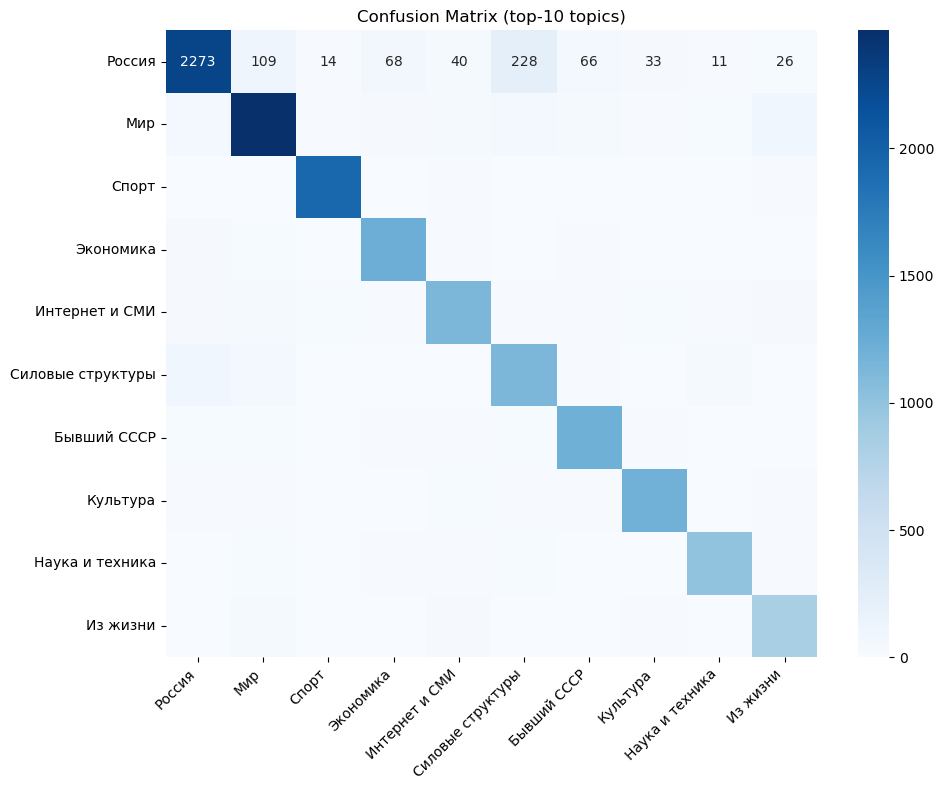

In [72]:
top_topics = pd.Series(y_test).value_counts().head(10).index
mask = np.isin(y_test, top_topics) & np.isin(y_pred_test, top_topics)
yt, yp = y_test[mask], y_pred_test[mask]

cm = confusion_matrix(yt, yp, labels=top_topics)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    xticklabels=top_topics,
    yticklabels=top_topics,
    annot=True,
    fmt="d",
    cmap="Blues",
)
plt.title("Confusion Matrix (top-10 topics)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Вне диагонали — путаница. Чаще путает смежные топики: Россия/Мир, Бизнес/Экономика, Бывший СССР/Крым. Спорт и Ценности распознаются стабильно.

Примеры ошибок классификации

In [73]:
wrong_mask = y_test != y_pred_test
wrong_indices = np.where(wrong_mask)[0][:5]

for i in wrong_indices:
    print(f"True: {y_test[i]} -> Pred: {y_pred_test[i]}")
    print(f"Text: {X_test[i][:150]}...")
    print()


True: Россия -> Pred: Дом
Text: многоэтажный дом омск произойти взрыв многоквартирный дом омск произойти взрыв бытовой газ сообщать интерфакс по данные агентство пострадать восемь че...

True: Мир -> Pred: Интернет и СМИ
Text: германия назвать главный мировой угроза самый больший проблема угрожать мировой стабильность кибернападение считать министр оборона германия урсула фо...

True: Интернет и СМИ -> Pred: Россия
Text: сотня ядовитый змея остаться без присмотр после смерть блогер власть ленинградский область не планировать решать ситуация частный дом погибший видеобл...

True: Россия -> Pred: Экономика
Text: управлять жкх сыграть лотерея за счёт должник потерпеть фиаско управлять предприятие жкх посёлок вершина тёи республика хакасия александр николаюк куп...

True: Силовые структуры -> Pred: Наука и техника
Text: китай протестировать серийный образец беспилотник ch-5 серийный образец китайский военный беспилотник ch-5 цайхун-5 совершить испытательный полёт сюже...



Ошибки типичны: тексты на стыке тем (Бизнес/Экономика), общие слова (Спорт/Интернет — тхэквондо, wtf), геополитика (Бывший СССР/Крым).

### Итоги

TF-IDF + LogReg с подобранными гиперпараметрами — F1_macro 0.82, accuracy 0.86. lru_cache обязателен для скорости лемматизации. Macro F1 подходит при дисбалансе классов. Путает в основном смежные топики (Россия/Мир, Бизнес/Экономика). 

Для улучшения — эмбеддинги!